# Cross-Africa Satellite Prediction: Dataset Construction (NBK 1)

This notebook builds the master analysis dataset by merging MOSAIKS satellite features with Global Data Lab (GDL) subnational development indicators. It identifies which MOSAIKS file is area-weighted versus population-weighted, loads five GDL indicator bundles, selects the survey year closest to 2019 for each region (within ±5 years), computes the gender schooling gap, and writes `labels.csv` plus two feature parquets that are used in downstream analysis.

---

### Import statements

In [30]:
import os
import pandas as pd
import numpy as np
import helpers

---

### Identifying the two MOSAIKS feature files

MOSAIKS ships two precomputed aggregations to GDL ADM1 boundaries: one area-weighted and one population-weighted (using GHS-POP density): `GHS_POP` indicates population-weighting, and the file without a suffix is area-weighted. Feature values differ meaningfully between files, confirming they encode distinct aggregations.

In [31]:
feat_area = pd.read_csv(os.path.join(helpers.MOSAIKS_DIR, "GDL_ADM1_polygon_X_creation.csv"))
feat_pop  = pd.read_csv(os.path.join(helpers.MOSAIKS_DIR, "GDL_ADM1_polygon_X_creation_GHS_POP.csv"))

for df in (feat_area, feat_pop):
    df.rename(columns={"GDLCODE": "gdlcode"}, inplace=True)
    if "GDLCODE.1" in df.columns:
        df.drop(columns=["GDLCODE.1"], inplace=True)
    df["gdlcode"] = df["gdlcode"].str.strip()

feat_cols = [c for c in feat_area.columns if c != "gdlcode"]
print(f"Feature columns per region: {len(feat_cols)}")
print(f"Regions in area-weighted file: {len(feat_area)}")
print(f"Regions in population-weighted file: {len(feat_pop)}")

Feature columns per region: 4000
Regions in area-weighted file: 1759
Regions in population-weighted file: 1759


This loads two 4,000-dimensional feature vectors per region for 1,759 ADM1 regions globally. Downstream analyses use the population-weighted version as the primary specification.

---

### Loading GDL indicator bundles (Africa, subnational)

The Global Data Lab distributes indicators as long-format CSVs (one row per region per year). The helper function restricts to `level == "Subnat"` and `continent == "Africa"`, lowercases columns, and keeps only the columns needed for this analysis.

In [32]:
wealth = helpers.load_gdl("Wealth Data v2.1.csv", ["iwi", "iwipov70"])
health = helpers.load_gdl("Health Data v2.1.csv", ["stunting", "u5mort", "dtp3age1"])
edwork = helpers.load_gdl("Education and Work Data v2.1.csv", ["eyef", "eyem", "lprimaryg",
                                                               "lprimaryb", "uprimaryg", "uprimaryb"])
hdi = helpers.load_gdl("Subnational HDI Data v10.2.csv", ["shdi"])
area_db = helpers.load_gdl("Area Database Data v441.csv", ["urban"])

for name, df in [("Wealth", wealth), ("Child health", health), ("Gender schooling gap", edwork),
                 ("SHDI", hdi), ("Urban share", area_db)]:
    print(f"{name} rows: {len(df)}")

Wealth rows: 2335
Child health rows: 2247
Gender schooling gap rows: 2335
SHDI rows: 16010
Urban share rows: 2248


Each bundle covers ~2,000–16,000 African subnational-year observations. The HDI file is much larger because the Subnational Human Development Index (SHDI) is modelled every year, while wealth/health/education are only populated for survey years.

---

### Picking the survey year closest to 2019

MOSAIKS imagery is from 2019. To align labels in time, the helper function keeps each region's observation closest to 2019 (ties broken by the earlier year) and drops anything more than 5 years away. For each outcome, the chosen survey year is recorded in an `<outcome>_year` column so later analyses can audit the temporal match.

In [33]:
wealth_cl = helpers.pick_closest_year(wealth, ["iwi", "iwipov70"])
health_cl = helpers.pick_closest_year(health, ["stunting", "u5mort", "dtp3age1"])
edwork_cl = helpers.pick_closest_year(edwork, ["eyef", "eyem", "lprimaryg", "lprimaryb", "uprimaryg", "uprimaryb"])
hdi_cl = helpers.pick_closest_year(hdi, ["shdi"])
area_cl = helpers.pick_closest_year(area_db, ["urban"])

edwork_cl["gap_eye"] = edwork_cl["eyef"] - edwork_cl["eyem"]
edwork_cl["gap_eye_year"] = edwork_cl["eyef_year"]
for name, df in [("Wealth", wealth_cl), ("Child health", health_cl), ("Gender schooling gap", edwork_cl),
                 ("SHDI", hdi_cl), ("Urban share", area_cl)]:
    print(f"{name} rows retained: {len(df)}")

Wealth rows retained: 480
Child health rows retained: 470
Gender schooling gap rows retained: 470
SHDI rows retained: 544
Urban share rows retained: 455


`gap_eye = eyef - eyem` is the derived gender-equity outcome: expected years of schooling for girls minus boys. Negative values indicate girls are disadvantaged.

---

### Assembling the master labels table

This step combines the four outcome bundles into a single wide table with one row per African ADM1 region. The region identifiers are concatenated and deduplicated to establish the universe (~564 regions), then each bundle's outcome columns and their `_year` metadata are left-joined onto the master. Regions missing a specific outcome get `NaN` for that column, and each downstream analysis handles its own per-outcome filtering.

In [34]:
all_codes = pd.concat([
    wealth_cl[["gdlcode","country","region","isocode3"]],
    health_cl[["gdlcode","country","region","isocode3"]],
    edwork_cl[["gdlcode","country","region","isocode3"]],
    hdi_cl   [["gdlcode","country","region","isocode3"]],
]).drop_duplicates(subset="gdlcode")

def add_cols(master, src, cols):
    year_cols = [f"{c}_year" for c in cols if f"{c}_year" in src.columns]
    merge_cols = ["gdlcode"] + [c for c in cols + year_cols if c in src.columns]
    return master.merge(src[merge_cols], on="gdlcode", how="left")

labels = all_codes.copy()
labels = add_cols(labels, wealth_cl, ["iwi","iwipov70"])
labels = add_cols(labels, health_cl, ["stunting","u5mort","dtp3age1"])
labels = add_cols(labels, edwork_cl, ["eyef","eyem","gap_eye","lprimaryg","lprimaryb","uprimaryg","uprimaryb"])
labels = add_cols(labels, hdi_cl, ["shdi"])
labels = add_cols(labels, area_cl, ["urban"])
print(f"Labels table shape: {labels.shape}")
labels.head()

Labels table shape: (564, 32)


,gdlcode,country,region,isocode3,iwi,iwipov70,iwi_year,iwipov70_year,stunting,u5mort,...,eyem_year,gap_eye_year,lprimaryg_year,lprimaryb_year,uprimaryg_year,uprimaryb_year,shdi,shdi_year,urban,urban_year
0,AGOr201,Angola,Cabinda,AGO,53.87,77.13,2016.0,2016.0,23.1,46.337,...,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,0.710,2019.0,81.76,2016.0
1,AGOr202,Angola,Zaire,AGO,40.27,89.43,2016.0,2016.0,25.7,56.102,...,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,0.643,2019.0,73.20,2016.0
2,AGOr203,Angola,Uige,AGO,23.24,95.29,2016.0,2016.0,41.4,73.230,...,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,0.565,2019.0,35.26,2016.0
3,AGOr204,Angola,Luanda,AGO,67.18,53.72,2016.0,2016.0,29.8,50.764,...,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,0.731,2019.0,96.55,2016.0
4,AGOr205,Angola,Kuanza Norte,AGO,30.36,90.98,2016.0,2016.0,46.3,86.938,...,2016.0,2016.0,2016.0,2016.0,2016.0,2016.0,0.566,2019.0,56.84,2016.0


This gives us one row per African ADM1 region, with one observation per outcome and the survey year used. Regions with no outcomes within ±5 years of 2019 are excluded.

---

### Coverage report

A quick audit of how many ADM1 regions and countries carry each outcome, plus the specific survey year(s) used for Nigeria. This confirms the pipeline retained the regions we expect and surfaces any coverage gaps before downstream analysis.

In [35]:
print(f"{'Outcome':<12} {'Regions':>8} {'Countries':>10} {'Nigeria n':>6} {'Nigeria year(s)':>12}")
nga_labels = labels[labels["isocode3"] == "NGA"]
for out in helpers.OUTCOMES:
    sub = labels.dropna(subset=[out])
    nga_sub = nga_labels.dropna(subset=[out])
    yr_col = f"{out}_year"
    yrs = sorted(nga_sub[yr_col].dropna().unique()) if yr_col in nga_sub.columns else []
    yr_str = ",".join(str(int(y)) for y in yrs) if yrs else "—"
    print(f"{out:<12} {len(sub):>8} {sub['isocode3'].nunique():>10} "
          f"{len(nga_sub):>6} {yr_str:>12}")

Outcome       Regions  Countries Nigeria n Nigeria year(s)
iwi               480         43     37         2018
iwipov70          477         42     37         2018
stunting          466         40     37         2018
u5mort            470         41     37         2018
dtp3age1          299         23     37         2018
gap_eye           470         41     37         2018
shdi              544         54     37         2019


Coverage is strongest for SHDI (54 countries) and weakest for DTP3 vaccination (only 23 countries). Nigeria has 37 regions across all outcomes, with 2018 as the dominant survey year.

---

### Visualizing coverage across outcomes

A quick bar chart makes the coverage asymmetry across outcomes immediately legible. DTP3 vaccination stands out as the weakest (only 23 countries), while SHDI covers nearly the entire continent.

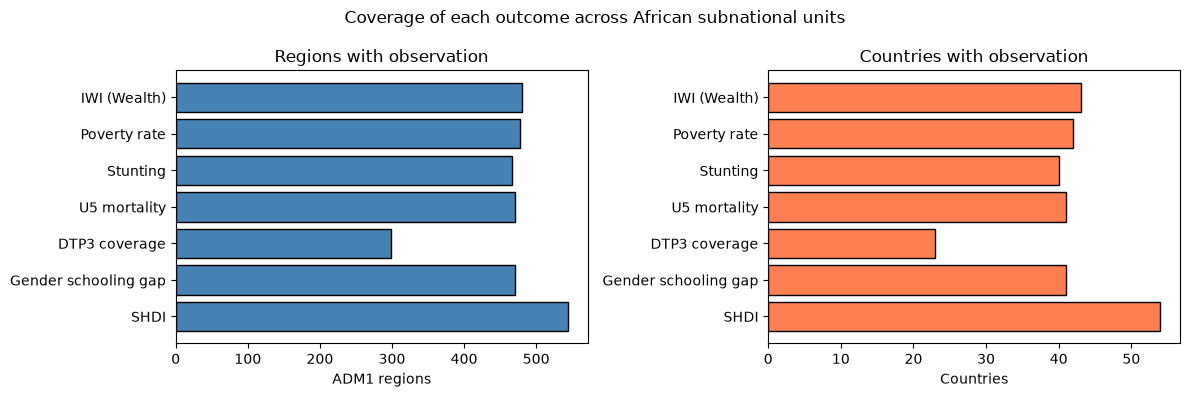

In [36]:
import matplotlib.pyplot as plt

coverage = []
for out in helpers.OUTCOMES:
    sub = labels.dropna(subset=[out])
    coverage.append({"outcome":  helpers.OUTCOME_LABELS[out], "regions":  len(sub),
                     "countries": sub["isocode3"].nunique()})
cov_df = pd.DataFrame(coverage)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh(cov_df["outcome"], cov_df["regions"],  color="steelblue", edgecolor="k")
ax[0].set_xlabel("ADM1 regions")
ax[0].set_title("Regions with observation")
ax[0].invert_yaxis()

ax[1].barh(cov_df["outcome"], cov_df["countries"], color="coral", edgecolor="k")
ax[1].set_xlabel("Countries")
ax[1].set_title("Countries with observation")
ax[1].invert_yaxis()

plt.suptitle("Coverage of each outcome across African subnational units")
plt.tight_layout()
plt.show()

Coverage is strongly asymmetric across outcomes: SHDI (modelled annually) reaches most regions, while DTP3 vaccination is only recorded for a narrow slice of countries. This asymmetry is important to note for downstream analysis.

---

### Saving outputs
The final labels table is written to `data/processed/labels.csv`, and the MOSAIKS features are merged onto it to produce two parquet files: one per aggregation. Parquet is used for the feature tables because they are smaller and faster to read than CSV at this width (4,000 columns), and preserves column types exactly. The Nigeria match count is printed as a sanity check: we expect all 37 Nigerian ADM1 units to appear in both feature files.

In [37]:
labels_out_path = os.path.join(helpers.PROC, "labels.csv")
labels.to_csv(labels_out_path, index=False)

for name, feat_df in [("area_weighted", feat_area), ("population_weighted", feat_pop)]:
    merged = labels.merge(feat_df, on="gdlcode", how="inner")
    merged.to_parquet(os.path.join(helpers.PROC, f"features_{name}.parquet"), index=False)
    nga_n = (merged["isocode3"] == "NGA").sum()
    print(f"{name}: {len(merged)} regions merged (Nigeria: {nga_n}/37)")

print(f"\nSaved labels and feature parquets.")

area_weighted: 538 regions merged (Nigeria: 37/37)
population_weighted: 538 regions merged (Nigeria: 37/37)

Saved labels and feature parquets.


`labels.csv` and the two feature parquets are the inputs for every subsequent notebook. Nigeria's 37 regions match 1:1 between MOSAIKS and GDL in both files.

---